# Parion: checking the reported results against the deposit

This notebook checks the numbers reported in Malgil and Tuğrul, "LiDAR-Integrated GIS Modelling of Urban Thresholds and Extramural Funerary Landscapes at Parion", against the deposited data. It recomputes them wherever that can be done in seconds, and it stops with an error if anything does not match.

| Section | Reported in | How it is checked |
|---|---|---|
| 1 | Input files | SHA-256 hashes against the run manifest |
| 2 | Table 1 | p-values and Holm correction recomputed from the deposited draws |
| 3 | Table S5 | the same, union test |
| 4 | Table S8 | the same, 0.4 m re-test |
| 5 | Tables S3, S4 | areas recomputed from the final viewshed rasters |
| 6 | Table 1, Section 4.5 | direct line of sight recomputed from the DEM |
| 7 | Figure 6, Section 3.2.2 | routes checked, and one route's time recomputed from the DEM |
| 8 | Section 3.1, Figure S11 | ground-return density from the deposited grids |

**Runtime:** under a minute or two. **Needs:** numpy, pandas, matplotlib, GDAL, GeoPandas (`environment.yml`). No GRASS.

**Layout:** this notebook sits in `walk-lcp-main/`, beside `W25_data_archive/`. Set `ARCHIVE` below if your folder differs.

**Full reruns.** The null draws themselves come from GRASS `r.viewshed`, so regenerating them takes longer: see `README.md` (about 6 min for the 2 m model and about 106 min for the 0.4 m re-test on 16 workers). Those commands were rerun on 6 November 2026 and reproduced the deposited tables and draws exactly.

In [1]:
import csv, hashlib, json, math, sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from osgeo import gdal

gdal.UseExceptions()
sys.path.insert(0, ".")
from viewshed_null import line_of_sight_profile, read_raster
from walk_lcp import tobler_speed, __version__ as lcp_version
from viewshed_null import __version__ as null_version

ARCHIVE = Path("..") / "W25_data_archive"
RES = ARCHIVE / "04_results"
NM = RES / "Null-model"
LCP = RES / "LCP_watermasked"
assert ARCHIVE.is_dir(), f"Set ARCHIVE: {ARCHIVE.resolve()} not found"

LOG = []
def check(name, ok, detail=""):
    LOG.append({"check": name, "result": "pass" if ok else "FAIL", "detail": detail})
    print(("pass  " if ok else "FAIL  ") + name + (f"  ({detail})" if detail else ""))
    assert ok, name

print("walk_lcp", lcp_version, "| viewshed_null", null_version, "| numpy", np.__version__)

walk_lcp 1.1.0 | viewshed_null 2.0.0 | numpy 2.5.4


## 1. Input files

The run manifest records the SHA-256 hash of every input to the least-cost paths.

In [2]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 24), b""):
            h.update(b)
    return h.hexdigest()

m = json.load(open(LCP / "manifest_watermasked.json", encoding="utf-8"))
for k, rel in (("dem", "02_processed/dem 04 Low Pass Filter_water_nodata.tif"), ("start", "03_gis_inputs/nodes_start.gpkg"), ("stop", "03_gis_inputs/nodes_stop.gpkg")):
    check(f"hash of {rel}", sha256(ARCHIVE / rel) == m["inputs"][k]["sha256"])
check("hash of the routes", sha256(LCP / "lcp_routes_watermasked.gpkg") == m["outputs"][0]["sha256"])
cfg = json.load(open("viewshed_foci_parion.json", encoding="utf-8"))
check("eleven foci with real coordinates", len(cfg["foci"]) == 11 and all(isinstance(f["x"], float) and isinstance(f["y"], float) for f in cfg["foci"]))
check("seven tested pairs", len(cfg["pairs"]) == 7)

pass  hash of 02_processed/dem 04 Low Pass Filter_water_nodata.tif
pass  hash of 03_gis_inputs/nodes_start.gpkg
pass  hash of 03_gis_inputs/nodes_stop.gpkg
pass  hash of the routes
pass  eleven foci with real coordinates
pass  seven tested pairs


## 2. Table 1: recomputed from the draws

`null_draws.npz` holds all 999 draws for each pair and statistic. The p-values below use only those draws and the observed values, with the formula in Section 3.2.3: `p_upper = (r_ge + 1)/(n + 1)`, `p_lower = (r_le + 1)/(n + 1)`, `p = min(1, 2 min(p_upper, p_lower))`, Holm across the seven pairs.

In [3]:
def holm(ps):
    ps = np.asarray(ps, float)
    adj, run = np.zeros(len(ps)), 0.0
    for k, i in enumerate(np.argsort(ps)):
        run = max(run, min(1.0, (len(ps) - k) * ps[i]))
        adj[i] = run
    return adj

def from_draws(run):
    z = np.load(NM / run / "null_draws.npz")
    t = pd.read_csv(NM / run / "results_table.csv")
    rows = []
    for _, r in t.iterrows():
        d = z[r["pair"].replace(" x ", "_x_") + "__" + r["statistic"]].astype(float)
        n, obs = len(d), float(r["observed"])
        ge, le = int((d >= obs - 1e-9).sum()), int((d <= obs + 1e-9).sum())
        p = min(1.0, 2 * min((ge + 1) / (n + 1), (le + 1) / (n + 1)))
        rows.append(dict(pair=r["pair"], statistic=r["statistic"], n=n, observed=obs, median=np.median(d), q95=np.percentile(d, 95), maximum=d.max(), ge=ge, p=p))
    out = pd.DataFrame(rows)
    out["holm"] = np.nan
    for s, g in out.groupby("statistic"):
        out.loc[g.index, "holm"] = holm(g.p.values)
    return out

D2 = from_draws("landmask_2m")
check("999 draws for every statistic, 2 m", (D2.n == 999).all())
NAMES = {"TavsanTum": "Tavşandere tumulus", "SouthGate": "southern gate", "SEGate": "southeastern gate", "CircularTower": "circular tower", "TasKule": "Taş Kule", "EastNecro": "Eastern Necropolis", "EastGate": "eastern gate"}
def nice(p):
    a, b = p.split(" x ")
    return NAMES[a] + " × " + NAMES[b]

# Table 1 as printed: % of smaller, Jaccard, null median, null 95th percentile, >= observed, p, Holm
T1 = {"TavsanTum x SouthGate": (83.2, 0.403, 21.9, 60.6, 0, 0.002, 0.014),
      "SouthGate x SEGate": (25.7, 0.133, 28.2, 66.5, 526, 0.948, 1.000),
      "CircularTower x TasKule": (18.8, 0.062, 1.4, 13.5, 14, 0.030, 0.180),
      "CircularTower x TavsanTum": (15.1, 0.043, 19.8, 49.5, 560, 0.880, 1.000),
      "EastNecro x SEGate": (8.1, 0.031, 21.5, 58.4, 656, 0.688, 1.000),
      "EastNecro x EastGate": (3.5, 0.017, 14.7, 47.3, 635, 0.730, 1.000),
      "TavsanTum x EastNecro": (2.5, 0.011, 7.1, 42.6, 592, 0.816, 1.000)}
rows = []
for p, e in T1.items():
    o = D2[(D2.pair == p) & (D2.statistic == "overlap_pct_smaller")].iloc[0]
    j = D2[(D2.pair == p) & (D2.statistic == "jaccard")].iloc[0]
    got = (round(o.observed, 1), round(j.observed, 3), round(o["median"], 1), round(o.q95, 1), o["ge"], round(o.p, 3), round(o.holm, 3))
    rows.append(dict(zip(("Pair", "% of smaller", "Jaccard", "Null median", "Null 95th", "≥ observed", "p", "Holm"), (nice(p),) + got)))
    check("Table 1: " + nice(p), all(abs(a - b) < 1e-6 for a, b in zip(got, e)))
pd.DataFrame(rows)

pass  999 draws for every statistic, 2 m
pass  Table 1: Tavşandere tumulus × southern gate
pass  Table 1: southern gate × southeastern gate
pass  Table 1: circular tower × Taş Kule
pass  Table 1: circular tower × Tavşandere tumulus
pass  Table 1: Eastern Necropolis × southeastern gate
pass  Table 1: Eastern Necropolis × eastern gate
pass  Table 1: Tavşandere tumulus × Eastern Necropolis


,Pair,% of smaller,Jaccard,Null median,Null 95th,≥ observed,p,Holm
0,Tavşandere tumulus × southern gate,83.2,0.403,21.9,60.6,0,0.002,0.014
1,southern gate × southeastern gate,25.7,0.133,28.2,66.5,526,0.948,1.000
2,circular tower × Taş Kule,18.8,0.062,1.4,13.5,14,0.030,0.180
3,circular tower × Tavşandere tumulus,15.1,0.043,19.8,49.5,560,0.880,1.000
4,Eastern Necropolis × southeastern gate,8.1,0.031,21.5,58.4,656,0.688,1.000
5,Eastern Necropolis × eastern gate,3.5,0.017,14.7,47.3,635,0.730,1.000
6,Tavşandere tumulus × Eastern Necropolis,2.5,0.011,7.1,42.6,592,0.816,1.000


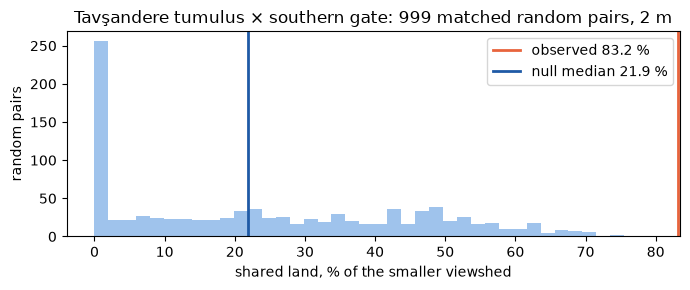

In [4]:
d = np.load(NM / "landmask_2m" / "null_draws.npz")["TavsanTum_x_SouthGate__overlap_pct_smaller"]
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(d, bins=40, color="#9fc3ec")
ax.axvline(83.2, color="#e8643c", lw=2, label="observed 83.2 %")
ax.axvline(np.median(d), color="#1f5aa6", lw=2, label=f"null median {np.median(d):.1f} %")
ax.set_xlabel("shared land, % of the smaller viewshed")
ax.set_ylabel("random pairs")
ax.set_title("Tavşandere tumulus × southern gate: 999 matched random pairs, 2 m")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Table S5: union test

In [5]:
S5 = {"CircularTower x TasKule": (68.2, 26.3, 58.3, 0, 0.002, 0.014), "CircularTower x TavsanTum": (65.8, 33.4, 60.6, 0, 0.002, 0.014),
      "TavsanTum x EastNecro": (32.6, 33.7, 70.9, 530, 0.940, 1.000), "EastNecro x EastGate": (26.2, 31.5, 57.6, 670, 0.660, 1.000),
      "EastNecro x SEGate": (21.7, 32.3, 61.1, 795, 0.410, 1.000), "TavsanTum x SouthGate": (20.5, 32.4, 61.6, 808, 0.384, 1.000),
      "SouthGate x SEGate": (16.1, 32.2, 62.0, 886, 0.228, 1.000)}
rows = []
for p, e in S5.items():
    o = D2[(D2.pair == p) & (D2.statistic == "union_ha")].iloc[0]
    got = (round(o.observed, 1), round(o["median"], 1), round(o.maximum, 1), o["ge"], round(o.p, 3), round(o.holm, 3))
    rows.append(dict(zip(("Pair", "Combined, 2 m (ha)", "Null median", "Largest of 999", "≥ observed", "p", "Holm"), (nice(p),) + got)))
    check("Table S5: " + nice(p), all(abs(a - b) < 1e-6 for a, b in zip(got, e)))
pd.DataFrame(rows)

pass  Table S5: circular tower × Taş Kule
pass  Table S5: circular tower × Tavşandere tumulus
pass  Table S5: Tavşandere tumulus × Eastern Necropolis
pass  Table S5: Eastern Necropolis × eastern gate
pass  Table S5: Eastern Necropolis × southeastern gate
pass  Table S5: Tavşandere tumulus × southern gate
pass  Table S5: southern gate × southeastern gate


,Pair,"Combined, 2 m (ha)",Null median,Largest of 999,≥ observed,p,Holm
0,circular tower × Taş Kule,68.2,26.3,58.3,0,0.002,0.014
1,circular tower × Tavşandere tumulus,65.8,33.4,60.6,0,0.002,0.014
2,Tavşandere tumulus × Eastern Necropolis,32.6,33.7,70.9,530,0.940,1.000
3,Eastern Necropolis × eastern gate,26.2,31.5,57.6,670,0.660,1.000
4,Eastern Necropolis × southeastern gate,21.7,32.3,61.1,795,0.410,1.000
5,Tavşandere tumulus × southern gate,20.5,32.4,61.6,808,0.384,1.000
6,southern gate × southeastern gate,16.1,32.2,62.0,886,0.228,1.000


## 4. Table S8: re-test at 0.4 m

The last column multiplies the p-value by the seven tests, capped at 1.

In [6]:
D4 = from_draws("landmask_0.4m_fragile")
S8 = {("TavsanTum x SouthGate", "overlap_pct_smaller"): (79.5, 16.5, 54.7, 77.0, 0, 0.002), ("TavsanTum x SouthGate", "jaccard"): (0.449, 0.054, 0.297, 0.451, 1, 0.004), ("TavsanTum x SouthGate", "overlap_ha"): (7.52, 1.16, 11.02, 21.91, 117, 0.236), ("TavsanTum x SouthGate", "union_ha"): (16.75, 25.72, 42.44, 49.95, 816, 0.368),
      ("CircularTower x TavsanTum", "overlap_pct_smaller"): (8.6, 13.3, 42.8, 57.8, 594, 0.812), ("CircularTower x TavsanTum", "jaccard"): (0.023, 0.043, 0.193, 0.245, 614, 0.772), ("CircularTower x TavsanTum", "overlap_ha"): (1.27, 1.07, 6.91, 8.84, 466, 0.934), ("CircularTower x TavsanTum", "union_ha"): (54.52, 26.34, 40.43, 52.62, 0, 0.002),
      ("CircularTower x TasKule", "overlap_pct_smaller"): (15.5, 1.1, 11.5, 21.5, 17, 0.036), ("CircularTower x TasKule", "jaccard"): (0.051, 0.003, 0.045, 0.075, 23, 0.048), ("CircularTower x TasKule", "overlap_ha"): (2.91, 0.07, 1.12, 2.33, 0, 0.002), ("CircularTower x TasKule", "union_ha"): (56.86, 20.39, 30.18, 51.84, 0, 0.002)}
DP = {"overlap_pct_smaller": 1, "jaccard": 3, "overlap_ha": 2, "union_ha": 2}
rows = []
for (p, s), e in S8.items():
    o = D4[(D4.pair == p) & (D4.statistic == s)].iloc[0]
    n = DP[s]
    got = (round(o.observed, n), round(o["median"], n), round(o.q95, n), round(o.maximum, n), o["ge"], round(o.p, 3))
    rows.append(dict(Pair=nice(p), Statistic=s, Observed=got[0], Median=got[1], Q95=got[2], Maximum=got[3], GE=got[4], p=got[5], p_x7=round(min(1, 7 * o.p), 3)))
    check(f"Table S8: {nice(p)}, {s}", all(abs(a - b) < 0.0011 * (10 ** (3 - n)) if i < 4 else abs(a - b) < 1e-6 for i, (a, b) in enumerate(zip(got, e))))
pd.DataFrame(rows)

pass  Table S8: Tavşandere tumulus × southern gate, overlap_pct_smaller
pass  Table S8: Tavşandere tumulus × southern gate, jaccard
pass  Table S8: Tavşandere tumulus × southern gate, overlap_ha
pass  Table S8: Tavşandere tumulus × southern gate, union_ha
pass  Table S8: circular tower × Tavşandere tumulus, overlap_pct_smaller
pass  Table S8: circular tower × Tavşandere tumulus, jaccard
pass  Table S8: circular tower × Tavşandere tumulus, overlap_ha
pass  Table S8: circular tower × Tavşandere tumulus, union_ha
pass  Table S8: circular tower × Taş Kule, overlap_pct_smaller
pass  Table S8: circular tower × Taş Kule, jaccard
pass  Table S8: circular tower × Taş Kule, overlap_ha
pass  Table S8: circular tower × Taş Kule, union_ha


,Pair,Statistic,Observed,Median,Q95,Maximum,GE,p,p_x7
0,Tavşandere tumulus × southern gate,overlap_pct_smaller,79.500,16.500,54.700,77.000,0,0.002,0.014
1,Tavşandere tumulus × southern gate,jaccard,0.449,0.054,0.297,0.451,1,0.004,0.028
2,Tavşandere tumulus × southern gate,overlap_ha,7.520,1.160,11.020,21.910,117,0.236,1.000
3,Tavşandere tumulus × southern gate,union_ha,16.750,25.720,42.440,49.950,816,0.368,1.000
4,circular tower × Tavşandere tumulus,overlap_pct_smaller,8.600,13.300,42.800,57.800,594,0.812,1.000
5,circular tower × Tavşandere tumulus,jaccard,0.023,0.043,0.193,0.245,614,0.772,1.000
6,circular tower × Tavşandere tumulus,overlap_ha,1.270,1.070,6.910,8.840,466,0.934,1.000
7,circular tower × Tavşandere tumulus,union_ha,54.520,26.340,40.430,52.620,0,0.002,0.014
8,circular tower × Taş Kule,overlap_pct_smaller,15.500,1.100,11.500,21.500,17,0.036,0.252
9,circular tower × Taş Kule,jaccard,0.051,0.003,0.045,0.075,23,0.048,0.336


## 5. Tables S3 and S4: from the final viewshed rasters

Each raster holds 1 = visible land, 0 = land not visible, 255 = water or no data.

In [7]:
V = RES / "Viewshed_landmasked_0.4m_rerun"
ds = gdal.Open(str(V / "CircularTower_land.tif"))
gt = ds.GetGeoTransform()
cell_ha = abs(gt[1] * gt[5]) / 1e4
vis = {f["name"]: gdal.Open(str(V / (f["name"] + "_land.tif"))).ReadAsArray() for f in cfg["foci"]}
land_ha = (vis["CircularTower"] != 255).sum() * cell_ha
check("land within the survey is 211.00 ha", abs(land_ha - 211.00) < 0.01, f"{land_ha:.2f} ha")
TS3 = {"CircularTower": (41.00, 19.4), "TasKule": (18.77, 8.9), "TavsanTum": (14.80, 7.0), "EastNecro": (11.41, 5.4), "SouthGate": (9.47, 4.5), "EastGate": (9.66, 4.6), "AcroKule": (3.72, 1.8), "WestGate": (3.85, 1.8), "SEGate": (6.48, 3.1), "NorthNecro": (2.70, 1.3), "SouthNecro": (0.47, 0.2)}
rows = []
for k, (ha, pc) in TS3.items():
    h = (vis[k] == 1).sum() * cell_ha
    rows.append(dict(Focus=k, Visible_ha=round(h, 2), Pct_of_land=round(100 * h / land_ha, 1)))
    check("Table S3: " + k, abs(round(h, 2) - ha) < 1e-6 and abs(round(100 * h / land_ha, 1) - pc) < 1e-6)
TS4 = {"TavsanTum x SouthGate": (7.52, 50.8, 79.5, 3.57), "CircularTower x TasKule": (2.91, 7.1, 15.5, 1.38), "SouthGate x SEGate": (1.76, 18.6, 27.1, 0.83), "CircularTower x TavsanTum": (1.27, 3.1, 8.6, 0.60), "EastNecro x SEGate": (0.43, 3.8, 6.7, 0.21), "EastNecro x EastGate": (0.20, 1.7, 2.0, 0.09), "TavsanTum x EastNecro": (0.12, 0.8, 1.1, 0.06)}
for p, e in TS4.items():
    a, b = p.split(" x ")
    sh = ((vis[a] == 1) & (vis[b] == 1)).sum() * cell_ha
    got = (round(sh, 2), round(100 * sh / ((vis[a] == 1).sum() * cell_ha), 1), round(100 * sh / ((vis[b] == 1).sum() * cell_ha), 1), round(100 * sh / land_ha, 2))
    check("Table S4: " + nice(p), all(abs(x - y) < 1e-6 for x, y in zip(got, e)))
pd.DataFrame(rows)

pass  land within the survey is 211.00 ha  (211.00 ha)
pass  Table S3: CircularTower
pass  Table S3: TasKule
pass  Table S3: TavsanTum
pass  Table S3: EastNecro
pass  Table S3: SouthGate
pass  Table S3: EastGate
pass  Table S3: AcroKule
pass  Table S3: WestGate
pass  Table S3: SEGate
pass  Table S3: NorthNecro
pass  Table S3: SouthNecro
pass  Table S4: Tavşandere tumulus × southern gate


pass  Table S4: circular tower × Taş Kule
pass  Table S4: southern gate × southeastern gate
pass  Table S4: circular tower × Tavşandere tumulus
pass  Table S4: Eastern Necropolis × southeastern gate
pass  Table S4: Eastern Necropolis × eastern gate


pass  Table S4: Tavşandere tumulus × Eastern Necropolis


,Focus,Visible_ha,Pct_of_land
0,CircularTower,41.00,19.4
1,TasKule,18.77,8.9
2,TavsanTum,14.80,7.0
3,EastNecro,11.41,5.4
4,SouthGate,9.47,4.5
5,EastGate,9.66,4.6
6,AcroKule,3.72,1.8
7,WestGate,3.85,1.8
8,SEGate,6.48,3.1
9,NorthNecro,2.70,1.3


## 6. Direct line of sight

Exact profile test on the 0.4 m DEM, both directions, observer and target at 1.7 m. No tested pair has a direct line of sight (Table 1). For the tumulus and the southern gate, Section 4.5 reports a block of 0.63 m about 56 m in front of the gate.

In [8]:
dem_r = read_raster(ARCHIVE / "02_processed" / "dem 04 Low Pass Filter.tif")
dem = np.where(dem_r.array == dem_r.nodata, np.nan, dem_r.array).astype(np.float64)
xy = {f["name"]: (f["x"], f["y"]) for f in cfg["foci"]}
for p in cfg["pairs"]:
    a, b = p["a"], p["b"]
    ab = line_of_sight_profile(dem, dem_r.gt, xy[a], xy[b], 1.7, 1.7)
    ba = line_of_sight_profile(dem, dem_r.gt, xy[b], xy[a], 1.7, 1.7)
    check(f"no line of sight: {NAMES[a]} × {NAMES[b]}", not ab["visible"] and not ba["visible"], f"clearance {ab['clearance_m']:.2f} m")
r = line_of_sight_profile(dem, dem_r.gt, xy["SouthGate"], xy["TavsanTum"], 1.7, 1.7)
check("tumulus × gate blocked by 0.63 m about 56 m from the gate", abs(r["clearance_m"] + 0.63) < 0.01 and abs(r["blocked_at_m"] - 56) < 1, f"{-r['clearance_m']:.2f} m at {r['blocked_at_m']:.1f} m")

pass  no line of sight: Tavşandere tumulus × southern gate  (clearance -0.63 m)
pass  no line of sight: southern gate × southeastern gate  (clearance -3.86 m)
pass  no line of sight: circular tower × Tavşandere tumulus  (clearance -2.40 m)
pass  no line of sight: Eastern Necropolis × southeastern gate  (clearance -1.30 m)
pass  no line of sight: Eastern Necropolis × eastern gate  (clearance -8.46 m)
pass  no line of sight: Tavşandere tumulus × Eastern Necropolis  (clearance -4.30 m)
pass  no line of sight: circular tower × Taş Kule  (clearance -6.02 m)
pass  tumulus × gate blocked by 0.63 m about 56 m from the gate  (0.63 m at 56.3 m)


## 7. Least-cost routes

The route counts and summaries come from the deposited comparison table. The last check recomputes one route's time from the DEM with Tobler's function, cell by cell along the stored line. To recompute every route, see `README.md`, section 2 (about 7 min).

In [9]:
routes = gpd.read_file(LCP / "lcp_routes_watermasked.gpkg")
cmp_ = pd.read_csv(LCP / "route_comparison.csv")
nd = cmp_[cmp_.masked_dist_m > 0]
x = nd[nd.nomask_water_m > 20]
sc = cmp_[(cmp_.start_name != cmp_.stop_name) & (cmp_.masked_dist_m > 0)]
check("238 routes", len(routes) == 238)
check("none unreachable", len(pd.read_csv(LCP / "lcp_routes_watermasked_unreachable.csv")) == 0)
check("7 same-point combinations, 231 non-trivial", (cmp_.masked_dist_m == 0).sum() == 7 and len(nd) == 231)
check("no route crosses mapped water", cmp_.masked_water_m.max() == 0)
check("33 routes would cross water without the mask", len(x) == 33, f"{x.nomask_water_m.min():.1f}-{x.nomask_water_m.max():.0f} m of water; others at most {nd[nd.nomask_water_m <= 20].nomask_water_m.max():.1f} m")
check("median cost of avoiding water 0.4 min (3.3 %)", round(x.d_time_mask_min.median(), 1) == 0.4 and round((100 * x.d_time_mask_min / x.nomask_time_min).median(), 1) == 3.3)
check("2 m check: median 1.6 %, 91 % within 3 %", round(sc.d_time_2m_vs_04m_pct.abs().median(), 1) == 1.6 and round(100 * (sc.d_time_2m_vs_04m_pct.abs() <= 3).mean()) == 91)
check("2 m check: median offset 2.4 m", round(sc.scale2m_mean_offset_m.median(), 1) == 2.4)
nds = gdal.Open(str(ARCHIVE / "02_processed" / "dem 04 Low Pass Filter_water_nodata.tif"))
g, z = nds.GetGeoTransform(), nds.ReadAsArray().astype(np.float64)
r = routes[routes.dist_m > 500].iloc[0]
pts = np.array(r.geometry.coords)[:, :2]
col = np.floor((pts[:, 0] - g[0]) / g[1]).astype(int)
row = np.floor((pts[:, 1] - g[3]) / g[5]).astype(int)
t = 0.0
for k in range(len(pts) - 1):
    dx = (col[k + 1] - col[k]) * g[1]
    dy = (row[k + 1] - row[k]) * g[5]
    d = math.hypot(dx, dy)
    t += d / tobler_speed((z[row[k + 1], col[k + 1]] - z[row[k], col[k]]) / d)
check(f"one route recomputed: {r.start_name} to {r.stop_name}", abs(t - r.time_s) < 0.01, f"{t:.2f} s against {r.time_s:.2f} s")

pass  238 routes
pass  none unreachable
pass  7 same-point combinations, 231 non-trivial
pass  no route crosses mapped water
pass  33 routes would cross water without the mask  (100.8-1159 m of water; others at most 2.6 m)
pass  median cost of avoiding water 0.4 min (3.3 %)
pass  2 m check: median 1.6 %, 91 % within 3 %
pass  2 m check: median offset 2.4 m


pass  one route recomputed: Possible Southern Gate to Eastern Necropolis  (581.58 s against 581.58 s)


## 8. Ground-return density

From the deposited 1 m grids. The grids were made from the full classified point cloud, which is too large to deposit (see `04_results/Ground_density/README_ground_density.txt`).

In [10]:
G = RES / "Ground_density"
gr = gdal.Open(str(G / "ground_returns_per_m2_1m.tif")).ReadAsArray()
al = gdal.Open(str(G / "all_returns_per_m2_1m.tif")).ReadAsArray()
m = gr >= 0
check("all returns 898 per m2", round(al[m].mean()) == 898, f"{al[m].mean():.1f}")
check("ground returns 559 per m2", round(gr[m].mean()) == 559, f"{gr[m].mean():.1f}")
check("ground share 62 %", round(100 * gr[m].sum() / al[m].sum()) == 62)
check("1 m land cells without a ground return 7.5 %", round(100 * (gr[m] == 0).mean(), 1) == 7.5)

pass  all returns 898 per m2  (897.6)
pass  ground returns 559 per m2  (558.9)
pass  ground share 62 %
pass  1 m land cells without a ground return 7.5 %


## Summary

In [11]:
S = pd.DataFrame(LOG)
print(f"{(S.result == 'pass').sum()} of {len(S)} checks passed")
assert (S.result == "pass").all()
print("ALL CHECKS PASSED")
S.result.value_counts()

73 of 73 checks passed
ALL CHECKS PASSED


result
pass    73
Name: count, dtype: int64